Original Dataset:
   X   Y
0  1   5
1  2   7
2  3   9
3  4  11
4  5  50
5  6  15
6  7  17
7  8  19
8  9  21

Detected Outliers:
   X   Y
4  5  50

Dataset After Removing Outliers:
   X   Y
0  1   5
1  2   7
2  3   9
3  4  11
5  6  15
6  7  17
7  8  19
8  9  21

Model Comparison:
        Dataset Model  Intercept  Coefficient     MSE  R2 Score
   With Outlier   OLS      7.111        2.000 135.210     0.165
   With Outlier Ridge      7.275        1.967 135.217     0.165
   With Outlier Lasso      7.861        1.850 135.360     0.164
Without Outlier   OLS      3.000        2.000   0.000     1.000
Without Outlier Ridge      3.164        1.967   0.008     1.000
Without Outlier Lasso      3.667        1.867   0.133     0.996


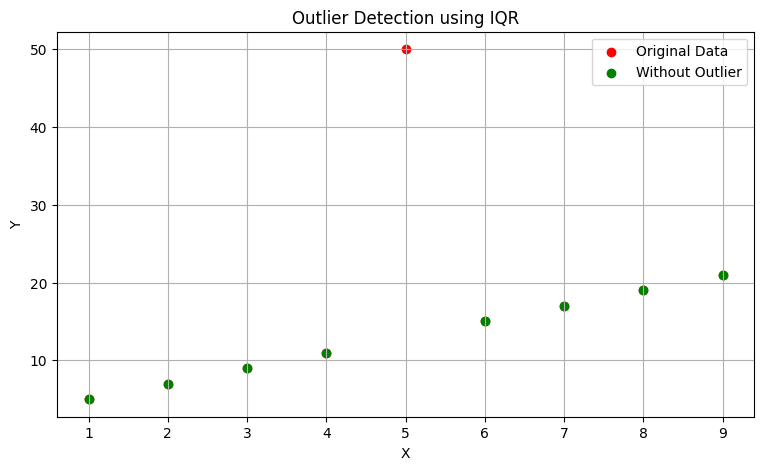

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score

# 1. Create dataset
data = {
    "X": [1, 2, 3, 4, 5, 6, 7, 8, 9],
    "Y": [5, 7, 9, 11, 50, 15, 17, 19, 21]
}

df = pd.DataFrame(data)

print("Original Dataset:")
print(df)

# 2. Detect outliers using IQR method
Q1 = df["Y"].quantile(0.25)
Q3 = df["Y"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df["Y"] < lower_limit) |
    (df["Y"] > upper_limit)
]

print("\nDetected Outliers:")
print(outliers)

# 3. Remove outliers
clean_df = df.drop(outliers.index)

print("\nDataset After Removing Outliers:")
print(clean_df)

# 4. Prepare original and cleaned datasets
datasets = {
    "With Outlier": df,
    "Without Outlier": clean_df
}

# 5. Apply OLS, Ridge and Lasso
models = {
    "OLS": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=1.0, max_iter=10000)
}

results = []

for dataset_name, dataset in datasets.items():

    X = dataset[["X"]]
    y = dataset["Y"]

    for model_name, model in models.items():

        model.fit(X, y)

        predictions = model.predict(X)

        mse = mean_squared_error(y, predictions)
        r2 = r2_score(y, predictions)

        results.append({
            "Dataset": dataset_name,
            "Model": model_name,
            "Intercept": model.intercept_,
            "Coefficient": model.coef_[0],
            "MSE": mse,
            "R2 Score": r2
        })

# 6. Display comparison
results_df = pd.DataFrame(results)

print("\nModel Comparison:")
print(results_df.round(3).to_string(index=False))

# 7. Visualize the dataset
plt.figure(figsize=(9, 5))

plt.scatter(df["X"], df["Y"], color="red",
            label="Original Data")

plt.scatter(clean_df["X"], clean_df["Y"],
            color="green", label="Without Outlier")

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Outlier Detection using IQR")
plt.legend()
plt.grid(True)
plt.show()
